First 5 Patient Records:
   Haemoglobin       RBC     Glucose  Cholesterol        BMI
0    14.245071  5.014672   70.139309   212.709658  28.753135
1    13.292604  5.136471   95.015624   162.335040  22.935821
2    14.471533  5.449831  110.131092   216.088178  25.384483
3    15.784545  5.432281  111.174515   230.669136  23.150899
4    13.148770  3.973398   98.748363   202.403047  23.262015

Dataset Shape: (200, 5)

Standardised Data:
   Haemoglobin       RBC   Glucose  Cholesterol       BMI
0     0.578767  0.276191 -1.521625     0.735502  0.849500
1    -0.104981  0.482377 -0.518096    -0.915547 -0.675688
2     0.741336  1.012849  0.091673     0.846234 -0.033696
3     1.683908  0.983140  0.133765     1.324132 -0.619299
4    -0.208235 -1.486529 -0.367515     0.397699 -0.590167

Covariance Matrix:
[[ 1.00502513  0.0956248  -0.1348713   0.06572625 -0.03136252]
 [ 0.0956248   1.00502513 -0.03278962 -0.10190536 -0.1427508 ]
 [-0.1348713  -0.03278962  1.00502513  0.10649153  0.02598337]
 [ 0.06

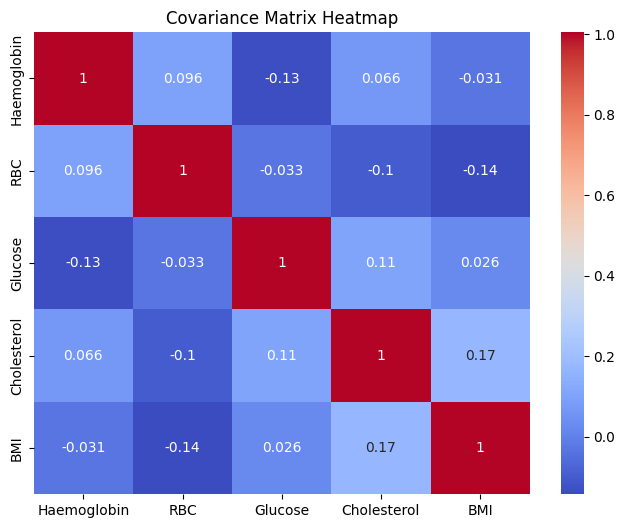


Correlation Matrix:
             Haemoglobin       RBC   Glucose  Cholesterol       BMI
Haemoglobin     1.000000  0.095147 -0.134197     0.065398 -0.031206
RBC             0.095147  1.000000 -0.032626    -0.101396 -0.142037
Glucose        -0.134197 -0.032626  1.000000     0.105959  0.025853
Cholesterol     0.065398 -0.101396  0.105959     1.000000  0.171162
BMI            -0.031206 -0.142037  0.025853     0.171162  1.000000


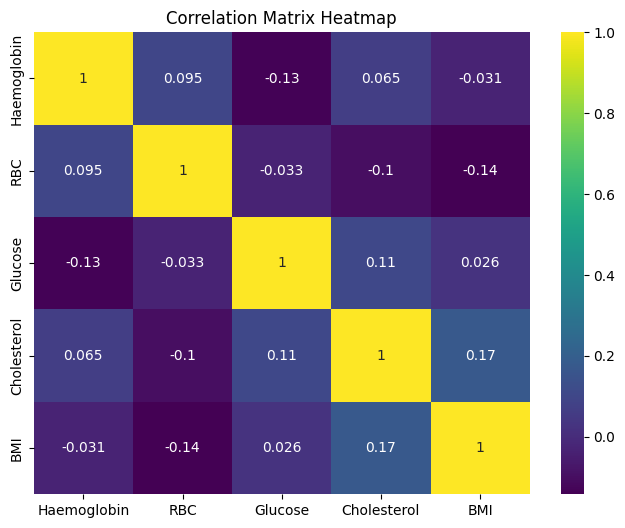


Eigenvalues:
[1.33177291 1.11589347 0.98782603 0.84192706 0.74770615]

Eigenvectors:
[[ 0.24613228 -0.74067287  0.23509617  0.26622328  0.51446823]
 [ 0.50426715 -0.0331167   0.53660467 -0.64546125 -0.20013277]
 [-0.36174773  0.45018115  0.66229107  0.10017661  0.46670193]
 [-0.51080366 -0.41117874  0.4104134   0.15383577 -0.61474145]
 [-0.54161955 -0.28031404 -0.2229722  -0.69195675  0.31551793]]

Explained Variance Percentage:
Principal Component 1: 26.50%
Principal Component 2: 22.21%
Principal Component 3: 19.66%
Principal Component 4: 16.75%
Principal Component 5: 14.88%


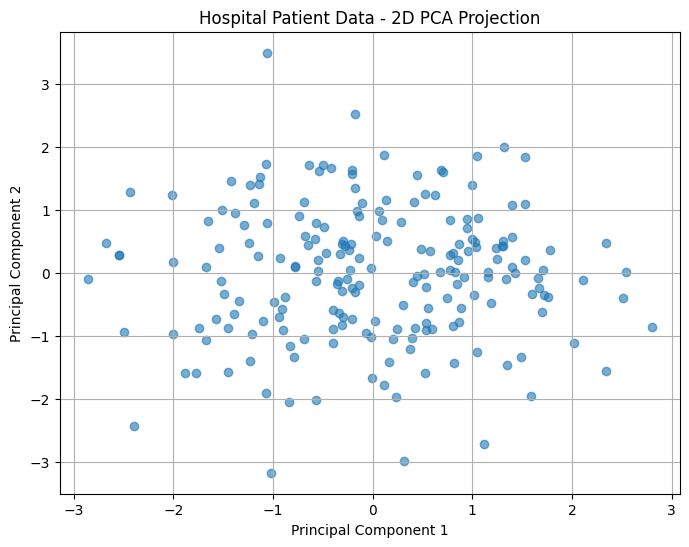

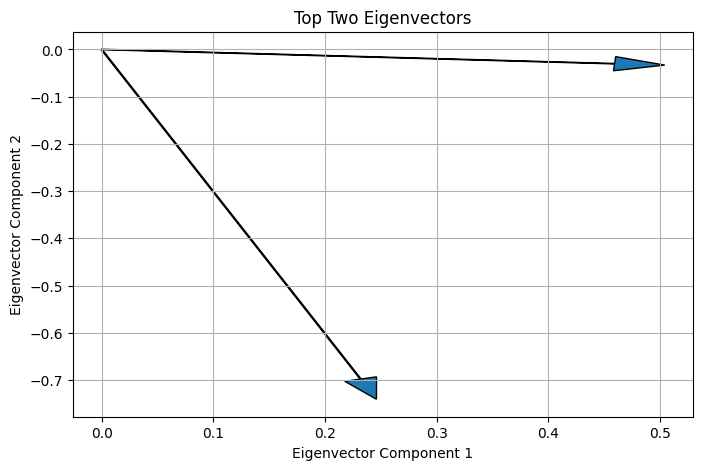

In [1]:

# Experiment 2: Covariance, Eigenvalues and Eigenvectors Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate hospital patient dataset (200 records)

np.random.seed(42)

data = {
    "Haemoglobin": np.random.normal(13.5, 1.5, 200),
    "RBC": np.random.normal(4.8, 0.6, 200),
    "Glucose": np.random.normal(110, 25, 200),
    "Cholesterol": np.random.normal(190, 30, 200),
    "BMI": np.random.normal(25, 4, 200)
}

df = pd.DataFrame(data)

print("First 5 Patient Records:")
print(df.head())

print("\nDataset Shape:", df.shape)


# 2. Standardise the data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
standardized_data = scaler.fit_transform(df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("\nStandardised Data:")
print(standardized_df.head())


# 3. Calculate Covariance Matrix

cov_matrix = np.cov(standardized_data, rowvar=False)

print("\nCovariance Matrix:")
print(cov_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cov_matrix,
    annot=True,
    cmap="coolwarm",
    xticklabels=df.columns,
    yticklabels=df.columns
)
plt.title("Covariance Matrix Heatmap")
plt.show()


# 4. Calculate Correlation Matrix

corr_matrix = standardized_df.corr()

print("\nCorrelation Matrix:")
print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="viridis",
    xticklabels=df.columns,
    yticklabels=df.columns
)
plt.title("Correlation Matrix Heatmap")
plt.show()


# 5. Calculate Eigenvalues and Eigenvectors

eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort in descending order
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)


# 6. Calculate Explained Variance

explained_variance = eigenvalues / np.sum(eigenvalues)

print("\nExplained Variance Percentage:")
for i, value in enumerate(explained_variance):
    print(f"Principal Component {i+1}: {value*100:.2f}%")


# 7. Project data onto the first two principal components

projected_data = np.dot(standardized_data, eigenvectors[:, :2])

plt.figure(figsize=(8, 6))
plt.scatter(
    projected_data[:, 0],
    projected_data[:, 1],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hospital Patient Data - 2D PCA Projection")
plt.grid()
plt.show()


# 8. Visualise the top two eigenvectors

plt.figure(figsize=(8, 5))

for i in range(2):
    plt.arrow(
        0, 0,
        eigenvectors[i, 0],
        eigenvectors[i, 1],
        head_width=0.03,
        length_includes_head=True
    )

plt.xlabel("Eigenvector Component 1")
plt.ylabel("Eigenvector Component 2")
plt.title("Top Two Eigenvectors")
plt.grid()
plt.show()
